In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin_min
import nltk
from nltk.util import ngrams
from nltk import pos_tag
from nltk.corpus import stopwords
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModel, AutoTokenizer
from transformers import XLMRobertaTokenizer, XLMRobertaForCausalLM
import os 

In [12]:
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\G34371231\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\G34371231\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\G34371231\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [13]:
path = os.getcwd() #path should be Evaluation folder
parent = os.path.join(path, os.pardir) #parent directory
memo_dataset_path = os.path.join(parent, "Data/Memo_Dataset.csv")
df = pd.read_csv(memo_dataset_path)
# Encode trigger as int (if needed)
df['Trigger'] = df['Trigger'].astype(int)

In [91]:
LANGUAGE = 'arabic' #english, arabic, both

In [92]:
if LANGUAGE == 'english':
    df['text'] = df['Question_eng']
elif LANGUAGE == 'arabic':
    df['text'] = df['Question']
else:
    df['text'] = df['Question_eng'] + ' ||| ' + df['Question']

print("Dataset shape:", df.shape)
print("Class distribution:\n", df['Trigger'].value_counts(normalize=True))

Dataset shape: (13142, 7)
Class distribution:
 Trigger
1    0.584919
0    0.415081
Name: proportion, dtype: float64


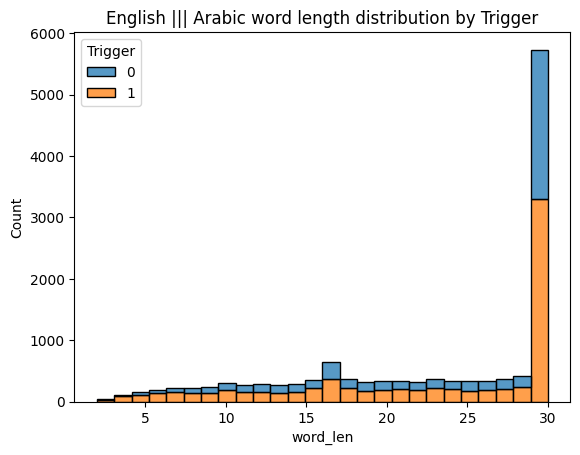

In [93]:
# lengths
df['char_len'] = df['text'].str.len()
df['word_len'] = df['text'].str.split().apply(len)

sns.histplot(df, x='word_len', hue='Trigger', multiple='stack')
plt.title('English ||| Arabic word length distribution by Trigger')
plt.show()

In [94]:
def get_top_ngrams(texts, n=1, top_k=20): #ngram analysis
    vec = CountVectorizer(ngram_range=(n,n), stop_words='english' if LANGUAGE in ['english','both'] else None)
    X = vec.fit_transform(texts)
    sum_words = X.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:top_k]

for n in [1,2,3]:
    print(f"Top {n}-grams overall:")
    print(get_top_ngrams(df['text'], n))
    print(f"Top {n}-grams for triggers:")
    trigger_texts = df[df['Trigger']==1]['text']
    print(get_top_ngrams(trigger_texts, n))
    print(f"Top {n}-grams for non-triggers:")
    non_trigger_texts = df[df['Trigger']==0]['text']
    print(get_top_ngrams(non_trigger_texts, n))


Top 1-grams overall:
[('من', np.int64(7989)), ('في', np.int64(7845)), ('هل', np.int64(3904)), ('انا', np.int64(2570)), ('مع', np.int64(2410)), ('على', np.int64(1729)), ('عليكم', np.int64(1695)), ('بعد', np.int64(1680)), ('ما', np.int64(1604)), ('السلام', np.int64(1576)), ('اعاني', np.int64(1568)), ('ان', np.int64(1510)), ('لا', np.int64(1494)), ('الم', np.int64(1475)), ('عند', np.int64(1365)), ('او', np.int64(1315)), ('عندي', np.int64(1312)), ('هذا', np.int64(1258)), ('طبيعي', np.int64(1041)), ('منذ', np.int64(1009))]
Top 1-grams for triggers:
[('من', np.int64(5054)), ('في', np.int64(4921)), ('هل', np.int64(1747)), ('مع', np.int64(1440)), ('انا', np.int64(1261)), ('اعاني', np.int64(1076)), ('الم', np.int64(1058)), ('على', np.int64(1033)), ('ما', np.int64(1026)), ('عليكم', np.int64(972)), ('بعد', np.int64(908)), ('السلام', np.int64(898)), ('لا', np.int64(830)), ('ان', np.int64(794)), ('عندي', np.int64(782)), ('عند', np.int64(758)), ('او', np.int64(744)), ('منذ', np.int64(670)), ('لدي', 

In [95]:
def compute_entropy(texts):
    tokens = ' '.join(texts).split()
    counts = np.array(list(Counter(tokens).values()))
    probs = counts / counts.sum()
    return -np.sum(probs * np.log2(probs))

entropy_trigger = compute_entropy(trigger_texts)
entropy_nontrigger = compute_entropy(non_trigger_texts)
print("Entropy Trigger:", entropy_trigger)
print("Entropy Non-Trigger:", entropy_nontrigger)

Entropy Trigger: 11.8800683057194
Entropy Non-Trigger: 11.71630591442351


In [96]:
tokenizer = XLMRobertaTokenizer.from_pretrained("xlm-roberta-base")#AutoTokenizer.from_pretrained('gpt-2'')
model = XLMRobertaForCausalLM.from_pretrained("xlm-roberta-base")#model = AutoModelForCausalLM.from_pretrained(lm_model_name)
model.eval()

def compute_ppl(texts):
    ppl_list = []
    for text in texts:
        encodings = tokenizer(text, return_tensors='pt')
        with torch.no_grad():
            outputs = model(**encodings, labels=encodings['input_ids'])
            loss = outputs.loss
        ppl = torch.exp(loss).item()
        ppl_list.append(ppl)
    return np.mean(ppl_list)

if LANGUAGE in ['english','both']:
    ppl_trigger = compute_ppl(trigger_texts[:50])  # sample to save time
    ppl_nontrigger = compute_ppl(non_trigger_texts[:50])
    print("Perplexity Trigger:", ppl_trigger)
    print("Perplexity Non-Trigger:", ppl_nontrigger)

If you want to use `XLMRobertaLMHeadModel` as a standalone, add `is_decoder=True.`


In [97]:
#pos tags english
if LANGUAGE in ['english','both']:
    trigger_tokens = [word for sent in trigger_texts for word in nltk.word_tokenize(sent)]
    nontrigger_tokens = [word for sent in non_trigger_texts for word in nltk.word_tokenize(sent)]
    
    trigger_pos = [pos for word,pos in pos_tag(trigger_tokens)]
    nontrigger_pos = [pos for word,pos in pos_tag(nontrigger_tokens)]
    
    trigger_pos_counts = Counter(trigger_pos)
    nontrigger_pos_counts = Counter(nontrigger_pos)
    
    print("Top POS Trigger:", trigger_pos_counts.most_common(10))
    print("Top POS Non-Trigger:", nontrigger_pos_counts.most_common(10))

In [98]:
from transformers import AutoTokenizer, AutoModel
import torch
import numpy as np

model_name = "xlm-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)
model.eval()

def embed_xlmr(texts):
    embeddings = []
    for text in texts:
        encoded = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=256)
        with torch.no_grad():
            output = model(**encoded)

        # Mean pooling
        last_hidden = output.last_hidden_state  # (1, seq_len, hidden)
        mask = encoded["attention_mask"].unsqueeze(-1)  # (1, seq_len, 1)
        masked_hidden = last_hidden * mask
        pooled = masked_hidden.sum(dim=1) / mask.sum(dim=1)
        embeddings.append(pooled.squeeze().numpy())
    return np.vstack(embeddings)




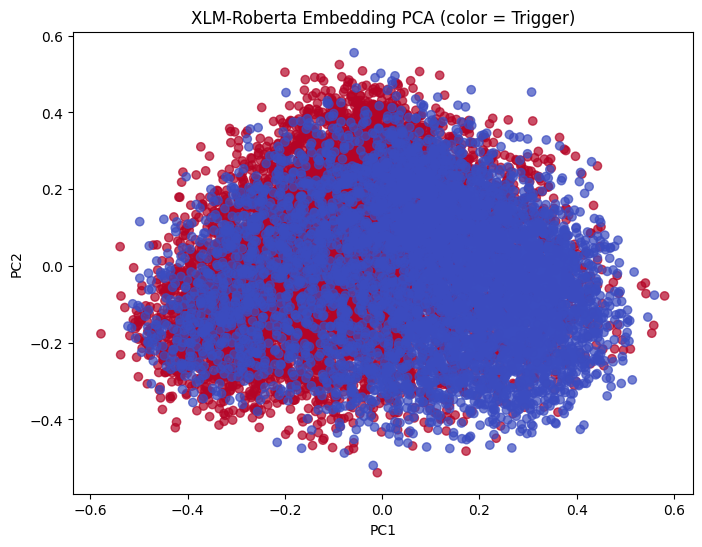

In [99]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
emb_2d = pca.fit_transform(embeddings)

plt.figure(figsize=(8,6))
plt.scatter(emb_2d[:,0], emb_2d[:,1], 
            c=df["Trigger"], cmap="coolwarm", alpha=0.7)
plt.title("XLM-Roberta Embedding PCA (color = Trigger)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()